In [ ]:
import numpy as np
import tensorflow as tf
import torch
import matplotlib.pyplot as plt
from numpy.polynomial import polynomial as P
from scipy.optimize import least_squares
from scipy.optimize import curve_fit
from scipy.stats import norm
import time
from IPython.display import display, clear_output
import torch.nn as nn
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader
import torch.nn.functional as nF
import torch.optim as optim

## Generate heatmaps and histograms

In [ ]:
# 1235 1770
file_path_1 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP0-0_scan0_raw_1of1.csv'
velopix_data_1 = np.loadtxt(fname=file_path_1, delimiter=",", skiprows=1)

from types import SimpleNamespace

header_1 = SimpleNamespace(
    min_thr    = 1235,
    max_thr    = 1770,
    step_size  =   5,
    vp         = 'Sensor 1',
    trim       =    0,
    readable   = 'DAC threshold scan for Sensor 1'
)

ana = Analyse()

out_folder = '/content/drive/MyDrive/magisterka/results_updated/'
import os
os.makedirs(out_folder, exist_ok=True)

# data saved to files: VP0-0_scan0_mean.csv, VP0-0_scan0_std.csv and VP0-0_scan0_rate.csv
d_mean, d_std, rate = ana.threshold_scan(
    velopix_data_1,
    header_1,
    save  = 0,
    slope = 'right',
    # path  = out_folder
)

Processing a threshold scan...
...time for computing mean & std is  0.19115567207336426
...computing noise rate, time elapsed:  0.04707455635070801


In [ ]:
rate.shape

(256, 256)

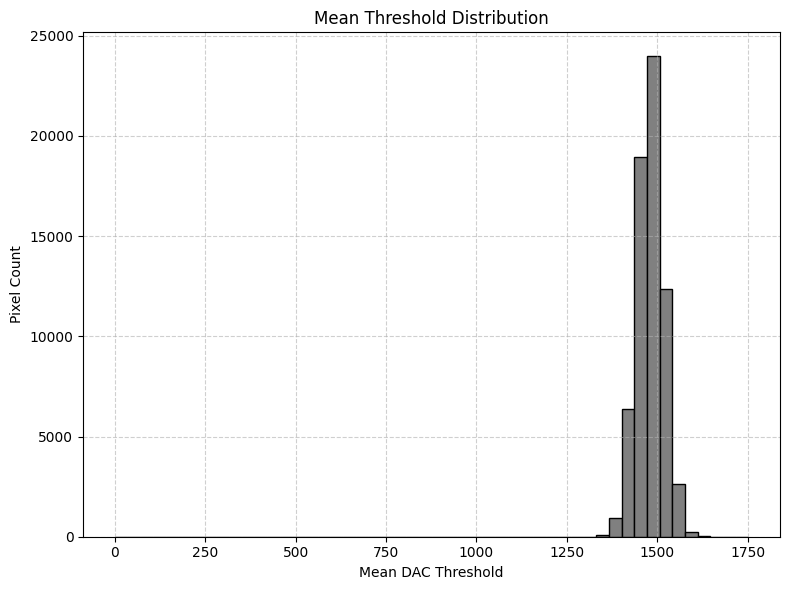

In [ ]:
import matplotlib.pyplot as plt

# Flatten the 256x256 matrix into a 1D array for histogram plotting
d_mean_flat = d_mean.flatten()

plt.figure(figsize=(8,6))
plt.hist(d_mean_flat, bins=50, color='grey', edgecolor='black')

plt.title("Mean Threshold Distribution")
plt.xlabel("Mean DAC Threshold")
plt.ylabel("Pixel Count")

plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


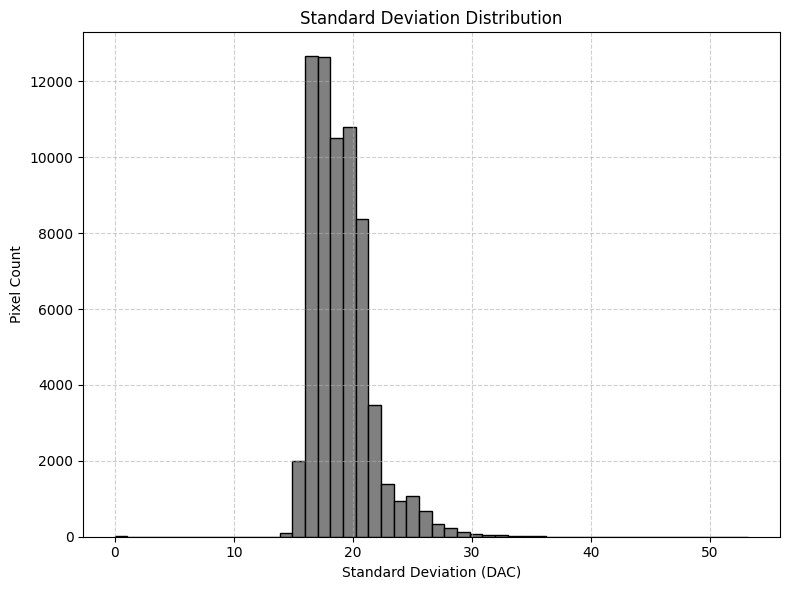

In [ ]:
import matplotlib.pyplot as plt

# Flatten the 256x256 matrix into a 1D array for histogram plotting
d_std_flat = d_std.flatten()

plt.figure(figsize=(8,6))
plt.hist(d_std_flat, bins=50, color='grey', edgecolor='black')

plt.title("Standard Deviation Distribution")
plt.xlabel("Standard Deviation (DAC)")
plt.ylabel("Pixel Count")

plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


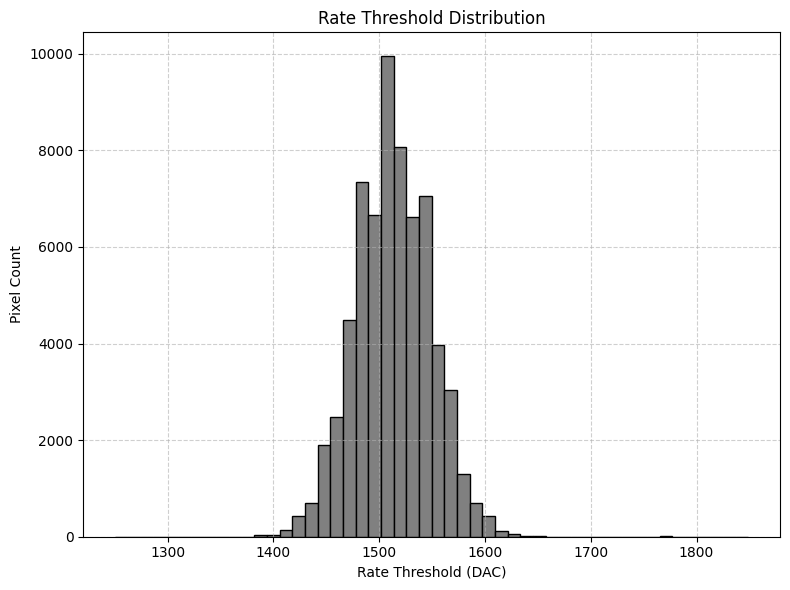

In [ ]:
import matplotlib.pyplot as plt

# Flatten the 256x256 matrix into a 1D array for histogram plotting
rate_flat = rate.flatten()

plt.figure(figsize=(8,6))
plt.hist(rate_flat, bins=50, color='grey', edgecolor='black')

plt.title("Rate Threshold Distribution")
plt.xlabel("Rate Threshold (DAC)")
plt.ylabel("Pixel Count")

plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


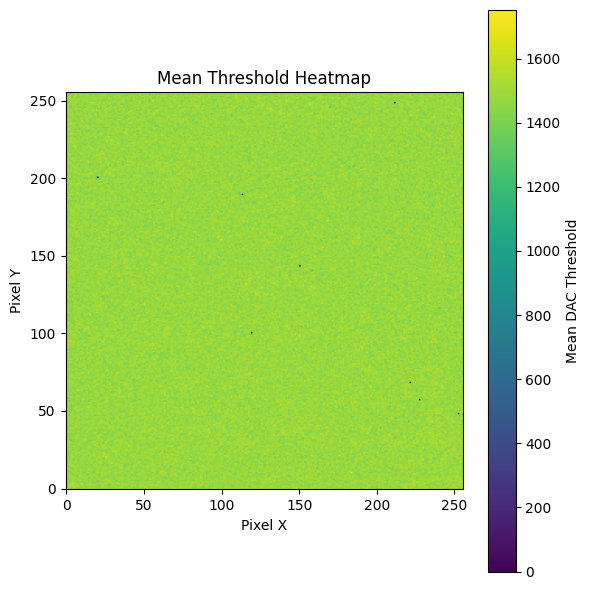

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.imshow(d_mean, cmap='viridis', origin='lower')
plt.colorbar(label="Mean DAC Threshold")

plt.title("Mean Threshold Heatmap")
plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")

plt.tight_layout()
plt.show()


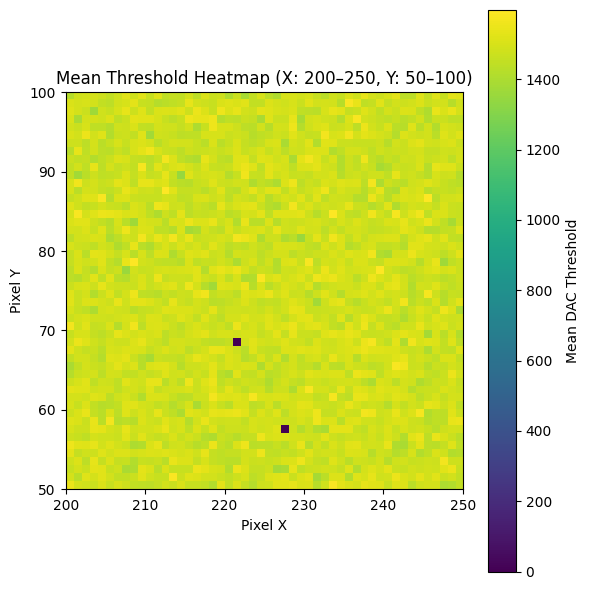

In [ ]:
import matplotlib.pyplot as plt

# Slice the region: x in [200,250), y in [50,100)
d_mean_slice = d_mean[50:100, 200:250]

plt.figure(figsize=(6,6))
plt.imshow(d_mean_slice, cmap='viridis', origin='lower',
           extent=[200, 250, 50, 100], aspect='equal')
plt.colorbar(label="Mean DAC Threshold")

plt.title("Mean Threshold Heatmap (X: 200–250, Y: 50–100)")
plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")

plt.tight_layout()
plt.show()


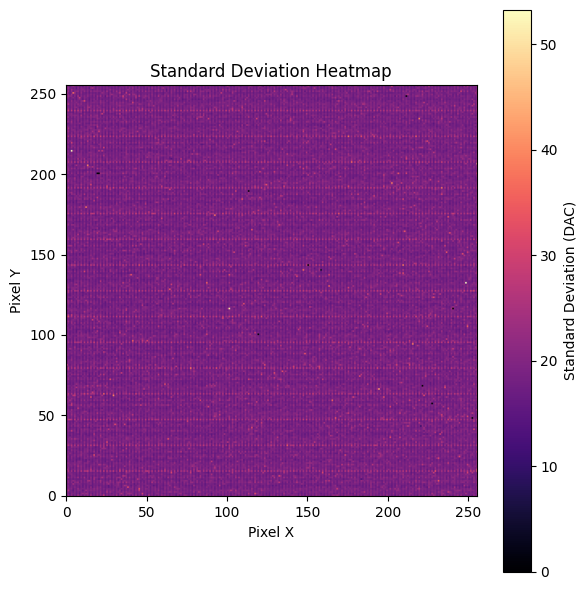

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.imshow(d_std, cmap='magma', origin='lower')
plt.colorbar(label="Standard Deviation (DAC)")

plt.title("Standard Deviation Heatmap")
plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")

plt.tight_layout()
plt.show()


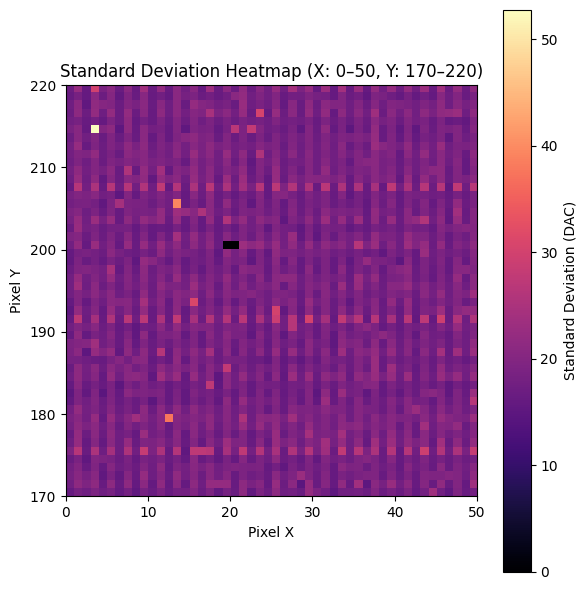

In [ ]:
import matplotlib.pyplot as plt

# Slice the region: y in [170,220), x in [0,50)
d_std_slice = d_std[170:220, 0:50]

plt.figure(figsize=(6,6))
plt.imshow(d_std_slice, cmap='magma', origin='lower',
           extent=[0, 50, 170, 220], aspect='equal')
plt.colorbar(label="Standard Deviation (DAC)")

plt.title("Standard Deviation Heatmap (X: 0–50, Y: 170–220)")
plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")

plt.tight_layout()
plt.show()


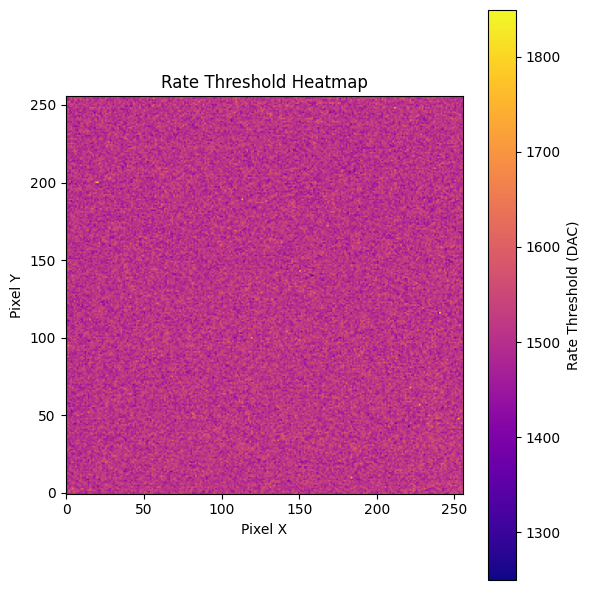

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.imshow(rate, cmap='plasma', origin='lower')
plt.colorbar(label="Rate Threshold (DAC)")

plt.title("Rate Threshold Heatmap")
plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")

plt.tight_layout()
plt.show()


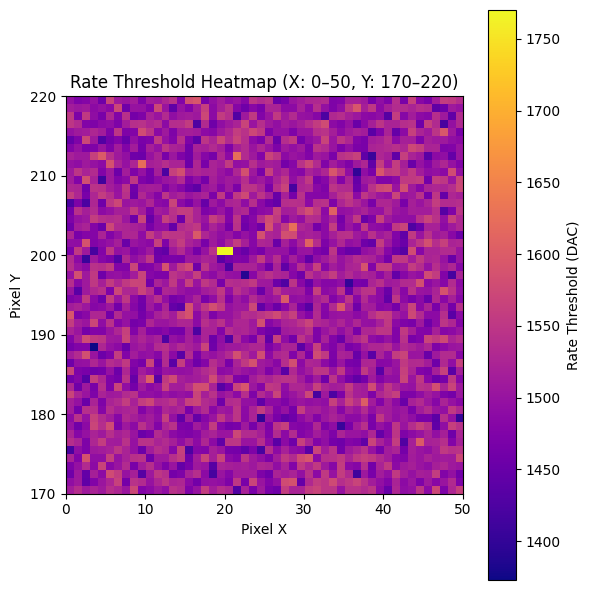

In [ ]:
import matplotlib.pyplot as plt

# Slice the region: y in [170,220), x in [0,50)
rate_slice = rate[170:220, 0:50]

plt.figure(figsize=(6,6))
plt.imshow(rate_slice, cmap='plasma', origin='lower',
           extent=[0, 50, 170, 220], aspect='equal')
plt.colorbar(label="Rate Threshold (DAC)")

plt.title("Rate Threshold Heatmap (X: 0–50, Y: 170–220)")
plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")

plt.tight_layout()
plt.show()


## Calculate how many of the scan counts are non-zero

In [ ]:
# 1395 1845
file_path_1 = '/content/drive/MyDrive/magisterka/data_velopix/Module29_VP0-0_scan0_raw.csv'
velopix_data_1 = np.loadtxt(fname=file_path_1, delimiter=",", skiprows=1)

In [ ]:
num_zeros = np.sum(velopix_data_1 == 0)
num_nonzeros = np.sum(velopix_data_1 != 0)
num_saturated = np.sum(velopix_data_1 >= 63.0)

total_values = velopix_data_1.size

perc_zeros = (num_zeros / total_values) * 100
perc_nonzeros = (num_nonzeros / total_values) * 100
perc_saturated = (num_saturated / total_values) * 100

print(f"Total values: {total_values}")
print(f"Zero values: {num_zeros} ({perc_zeros:.2f}%)")
print(f"Non-zero values: {num_nonzeros} ({perc_nonzeros:.2f}%)\n")

print(f"Saturated values (count 63): {num_saturated} ({perc_saturated:.2f}%)")

Total values: 5898240
Zero values: 4477103 (75.91%)
Non-zero values: 1421137 (24.09%)

Saturated values (count 63): 945681 (16.03%)


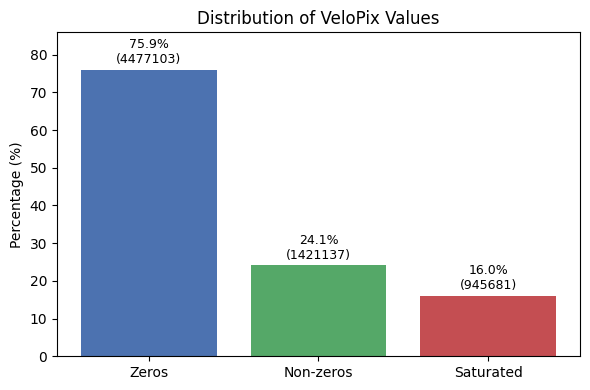

In [ ]:
# Bar chart comparing the counts
import numpy as np
import matplotlib.pyplot as plt

# Your calculations
num_zeros = np.sum(velopix_data_1 == 0)
num_nonzeros = np.sum(velopix_data_1 != 0)
num_saturated = np.sum(velopix_data_1 >= 63.0)

total_values = velopix_data_1.size

perc_zeros = (num_zeros / total_values) * 100
perc_nonzeros = (num_nonzeros / total_values) * 100
perc_saturated = (num_saturated / total_values) * 100

# Data for plotting
categories = ["Zeros", "Non-zeros", "Saturated"]
counts = [num_zeros, num_nonzeros, num_saturated]
percentages = [perc_zeros, perc_nonzeros, perc_saturated]

# Plot
fig, ax = plt.subplots(figsize=(6,4))
bars = ax.bar(categories, percentages, color=["#4C72B0", "#55A868", "#C44E52"])

# Annotate bars
for bar, pct, count in zip(bars, percentages, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f"{pct:.1f}%\n({count})",
            ha="center", va="bottom", fontsize=9)

ax.set_ylabel("Percentage (%)")
ax.set_title("Distribution of VeloPix Values")
plt.ylim(0, max(percentages) + 10)
plt.tight_layout()
plt.show()


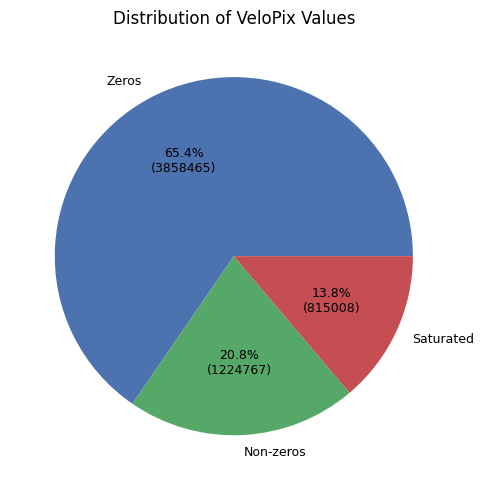

In [ ]:
# Pie chart comparing the counts
import numpy as np
import matplotlib.pyplot as plt

# Your calculations
num_zeros = np.sum(velopix_data_1 == 0)
num_nonzeros = np.sum(velopix_data_1 != 0)
num_saturated = np.sum(velopix_data_1 >= 63.0)

total_values = velopix_data_1.size

perc_zeros = (num_zeros / total_values) * 100
perc_nonzeros = (num_nonzeros / total_values) * 100
perc_saturated = (num_saturated / total_values) * 100

# Data for plotting
categories = ["Zeros", "Non-zeros", "Saturated"]
counts = [num_zeros, num_nonzeros, num_saturated]
percentages = [perc_zeros, perc_nonzeros, perc_saturated]

# Pie chart
fig, ax = plt.subplots(figsize=(5,5))
wedges, texts, autotexts = ax.pie(
    counts,
    labels=categories,
    autopct=lambda pct: f"{pct:.1f}%\n({int(round(pct*total_values/100))})",
    colors=["#4C72B0", "#55A868", "#C44E52"],
    textprops={"fontsize": 9}
)

ax.set_title("Distribution of VeloPix Values")
plt.tight_layout()
plt.show()


## Print example pixel's data

In [ ]:
# Import data for X different sensors

# 1395 1845
file_path_1 = '/content/drive/MyDrive/magisterka/data_velopix/Module29_VP0-0_scan0_raw.csv'
velopix_data_1 = np.loadtxt(fname=file_path_1, delimiter=",", skiprows=1)

# 1235 1790
file_path_2 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP3-1_scan0_raw_1of1.csv'
velopix_data_2 = np.loadtxt(fname=file_path_2, delimiter=",", skiprows=1)


sensor_stack_1 = reshape_sensor_data(velopix_data_1, sensor_min=1395, sensor_max=1845)
sensor_stack_2 = reshape_sensor_data(velopix_data_2, sensor_min=1235, sensor_max=1790)

In [ ]:
file_path_1 = '/content/drive/MyDrive/magisterka/data_velopix/Module29_VP0-0_scan0_raw.csv'
velopix_data_1 = np.loadtxt(fname=file_path_1, delimiter=",", skiprows=1)
sensor_stack_1 = reshape_sensor_data(velopix_data_1, sensor_min=1395, sensor_max=1845)
sensor_stack_1[:, 0, 0]

array([ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
        0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
        0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
        0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  5., 63.,
       63., 63., 63., 63., 63., 63., 63., 63., 63., 63., 63., 63., 13.,
        1.,  1.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
        0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.])

## Bulk copy paste

In [ ]:
# Import data for X different sensors

# 1395 1845
file_path_1 = '/content/drive/MyDrive/magisterka/data_velopix/Module29_VP0-0_scan0_raw.csv'
velopix_data_1 = np.loadtxt(fname=file_path_1, delimiter=",", skiprows=1)

# 1235 1790
file_path_2 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP3-1_scan0_raw_1of1.csv'
velopix_data_2 = np.loadtxt(fname=file_path_2, delimiter=",", skiprows=1)

# 1290 1885
file_path_3 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP3-0_scan0_raw_1of1.csv'
velopix_data_3 = np.loadtxt(fname=file_path_3, delimiter=",", skiprows=1)

# 1340 1980
file_path_4 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP2-2_scan0_raw_1of1.csv'
velopix_data_4 = np.loadtxt(fname=file_path_4, delimiter=",", skiprows=1)

# 1195 1780
file_path_5 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP2-1_scan0_raw_1of1.csv'
velopix_data_5 = np.loadtxt(fname=file_path_5, delimiter=",", skiprows=1)

# 1145 1705
file_path_6 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP3-2_scan0_raw_1of1.csv'
velopix_data_6 = np.loadtxt(fname=file_path_6, delimiter=",", skiprows=1)



sensor_stack_1 = reshape_sensor_data(velopix_data_1, sensor_min=1395, sensor_max=1845)
sensor_stack_2 = reshape_sensor_data(velopix_data_2, sensor_min=1235, sensor_max=1790)
sensor_stack_3 = reshape_sensor_data(velopix_data_3, sensor_min=1290, sensor_max=1885)
sensor_stack_4 = reshape_sensor_data(velopix_data_4, sensor_min=1340, sensor_max=1980)
sensor_stack_5 = reshape_sensor_data(velopix_data_5, sensor_min=1195, sensor_max=1780)
sensor_stack_6 = reshape_sensor_data(velopix_data_6, sensor_min=1145, sensor_max=1705)


# Prepare headers for these 6 sensors to count rate using Analyze class

from types import SimpleNamespace

header_1 = SimpleNamespace(
    min_thr    = 1395,
    max_thr    = 1845,
    step_size  =   5,
    vp         = 'Sensor 1',
    trim       =    0,
    readable   = 'DAC threshold scan for Sensor 1'
)

header_2 = SimpleNamespace(
    min_thr    = 1235,
    max_thr    = 1790,
    step_size  =   5,
    vp         = 'Sensor 2',
    trim       =    0,
    readable   = 'DAC threshold scan for Sensor 2'
)

header_3 = SimpleNamespace(
    min_thr    = 1290,
    max_thr    = 1885,
    step_size  =   5,
    vp         = 'Sensor 3',
    trim       =    0,
    readable   = 'DAC threshold scan for Sensor 3'
)

header_4 = SimpleNamespace(
    min_thr    = 1340,
    max_thr    = 1980,
    step_size  =   5,
    vp         = 'Sensor 4',
    trim       =    0,
    readable   = 'DAC threshold scan for Sensor 4'
)

header_5 = SimpleNamespace(
    min_thr    = 1195,
    max_thr    = 1780,
    step_size  =   5,
    vp         = 'Sensor 5',
    trim       =    0,
    readable   = 'DAC threshold scan for Sensor 5'
)

header_6 = SimpleNamespace(
    min_thr    = 1145,
    max_thr    = 1705,
    step_size  =   5,
    vp         = 'Sensor 6',
    trim       =    0,
    readable   = 'DAC threshold scan for Sensor 6'
)

data_list = [
    velopix_data_1,
    velopix_data_2,
    velopix_data_3,
    velopix_data_4,
    velopix_data_5,
    velopix_data_6,
]

header_list = [
    header_1,
    header_2,
    header_3,
    header_4,
    header_5,
    header_6,
]


# Generate rates for each sensor
ana = Analyse()
out_folder = '/content/drive/MyDrive/magisterka/results_sensors/'

rate_list = []
for data, hdr in zip(data_list, header_list):
    _, _, rate = ana.threshold_scan(
        data,
        hdr,
        save  = 0,
        slope = 'right',
        path  = out_folder
    )
    rate_list.append(rate)

## Analyze class and utils

In [ ]:
import time
import numpy as np
import glob as glob
import matplotlib.pyplot as plt


class Analyse():
    def __init__(
        self
    ):
        """
        """

    def threshold_scan(self, data, header, save = 1, slope = 'right', path = ''):
        print("Processing a threshold scan...")

        start = time.time()
        thr_range = np.arange(header.max_thr , header.min_thr , -header.step_size)
        data = data.astype(dtype = np.uint32).reshape((-1,256,256))
        d_mean, d_std = self.threshold_mean_std(data, thr_range)

        end = time.time()
        print("...time for computing mean & std is ", end - start)

        if save == 1:
            start = time.time()
            np.savetxt(path + header.vp + '_scan' + str(header.trim) + '_mean.csv', d_mean, delimiter = ',',
                    header = header.readable, fmt = '%.2f')
            np.savetxt(path + header.vp + '_scan' + str(header.trim) + '_std.csv', d_std, delimiter = ',',
                    header = header.readable, fmt = '%.2f')
            end = time.time()
            print("...saving mean & std, time elapsed: ", end - start)

        start = time.time()
        rate = self.threshold_rate(data, header.min_thr, header.max_thr, header.step_size, slope = slope)

        if save == 1:
            np.savetxt(path + header.vp + '_scan' + str(header.trim) + '_rate.csv', rate, delimiter = ',',
                    header = header.readable, fmt = '%.u')
        end = time.time()
        print("...computing noise rate, time elapsed: ", end - start)
        return d_mean, d_std, rate

    def generate_thr_recipe(self, dmean, header, cond, path = '') -> int:
        print(f"Generating threshold for {cond} DAC threshold ...")
        mdmean = np.mean(dmean, where = dmean != 0)
        thr = np.array([mdmean + cond])
        print(f'... computed threshold at {thr} DAC')
        np.savetxt(path + header.vp + '_threshold_recipe.csv', thr, fmt = '%.u')
        return thr

    def zeros(self, a, b):
        return np.zeros([a, b])

    def threshold_rate(self, data, min_thr, max_thr, step_size, slope = 'right'):
        if slope == 'left':
            data = np.flip(data, axis = 0)
        satmax = np.argmax(data > 31.5, axis = 0)
        #satmax[satmax == 0] = np.nan
        slopemax_l = np.float32(data[satmax, np.arange(256)[:, np.newaxis], np.arange(256)])
        slopemax_h = np.float32(data[satmax - 1, np.arange(256)[:, np.newaxis], np.arange(256)])
        grad = (slopemax_h - slopemax_l)/(step_size)
        if slope == 'right':
            dacmax = (max_thr - satmax * step_size)
        elif slope == 'left':
            dacmax = (min_thr + satmax * step_size)
        #satmax_dac[satmax_dac == 1950] = 0
        grad[grad == 0.0] = float('inf')
        slopemid = np.round(dacmax - (slopemax_l - 31.5)/grad)
        return slopemid

    def threshold_mean_std(self, data, thr_range):
        if data.dtype != np.uint32:
            data = data.astype(dtype = np.uint32)

        d_total = np.sum(data, axis = 0, dtype = np.float32)
        d_total[d_total == 0] = np.nan
        d_times_thr = data * thr_range[:, np.newaxis, np.newaxis]
        d_integral = np.sum(d_times_thr, axis = 0)
        d_mean = np.divide(d_integral, d_total)#, where = (d_total != 0))

        m_squared = np.array([np.full((256,256), thr) - d_mean for thr in thr_range]) ** 2
        d_times_squared = data * m_squared
        d_integral = np.sum(d_times_squared, axis = 0)
        d_sigma = np.sqrt(d_integral/d_total)

        d_mean = np.nan_to_num(d_mean, nan = 0)#.astype(np.uint32)
        d_sigma = np.nan_to_num(d_sigma, nan = 0)

        return d_mean, d_sigma


    def threshold_std(self, data, thr_range):
        if data.dtype != np.uint32:
            data = data.astype(dtype = np.uint32)
        m_squared = np.array([np.full((256,256), thr) - d_mean for thr in thr_range]) ** 2
        d_times_squared = data * m_squared
        d_integral = np.sum(d_times_squared, axis = 0)
        d_sigma = np.sqrt(d_integral / d_total)

    def mean_std(self, scan, precision = 2, skip_zeros = False):
        try:
            if skip_zeros == False:
                scan_mean = round(np.nanmean(scan), precision)
                scan_std = round(np.nanstd(scan), precision)
            else:
                scan_mean = round(np.nanmean(scan[scan!=0]), precision)
                scan_std = round(np.nanstd(scan[scan!=0]), precision)
        except:
            scan_mean, scan_std = np.nan, np.nan
        return scan_mean, scan_std


In [ ]:
import numpy as np

def reshape_sensor_data(raw_data: np.ndarray,
                        sensor_min: int,
                        sensor_max: int,
                        step: int = 5,
                        height: int = 256,
                        width: int = 256) -> np.ndarray:
    """
    Reshape a flat Velopix readout into (n_steps, height, width).

    Parameters
    ----------
    raw_data : np.ndarray
        Flat array of length n_steps * height * width.
    sensor_min : int
        Lowest DAC threshold in this scan.
    sensor_max : int
        Highest DAC threshold in this scan.
    step : int, optional
        DAC increment size (default=5).
    height, width : int, optional
        Spatial dimensions (default=256×256).

    Returns
    -------
    data3d : np.ndarray
        Array of shape (n_steps, height, width), where
           n_steps = (sensor_max - sensor_min) // step.

    Raises
    ------
    ValueError
        If raw_data.size doesn’t equal n_steps*height*width.
    """
    n_steps = (sensor_max - sensor_min) // step
    expected = n_steps * height * width
    if raw_data.size != expected:
        raise ValueError(f"Expected {expected} elements for a {n_steps}×{height}×{width} volume, "
                         f"but got {raw_data.size}")
    return raw_data.reshape(n_steps, height, width)


## Import training data

In [ ]:
# Import data for 10 different sensors

# 1395 1845
file_path_1 = '/content/drive/MyDrive/magisterka/data_velopix/Module29_VP0-0_scan0_raw.csv'
velopix_data_1 = np.loadtxt(fname=file_path_1, delimiter=",", skiprows=1)

# 1235 1790
file_path_2 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP3-1_scan0_raw_1of1.csv'
velopix_data_2 = np.loadtxt(fname=file_path_2, delimiter=",", skiprows=1)

# 1290 1885
file_path_3 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP3-0_scan0_raw_1of1.csv'
velopix_data_3 = np.loadtxt(fname=file_path_3, delimiter=",", skiprows=1)

# 1340 1980
file_path_4 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP2-2_scan0_raw_1of1.csv'
velopix_data_4 = np.loadtxt(fname=file_path_4, delimiter=",", skiprows=1)

# 1195 1780
file_path_5 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP2-1_scan0_raw_1of1.csv'
velopix_data_5 = np.loadtxt(fname=file_path_5, delimiter=",", skiprows=1)

# 1145 1705
file_path_6 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP3-2_scan0_raw_1of1.csv'
velopix_data_6 = np.loadtxt(fname=file_path_6, delimiter=",", skiprows=1)

# 1185 1735
file_path_7 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP0-1_scan0_raw_1of1.csv'
velopix_data_7 = np.loadtxt(fname=file_path_7, delimiter=",", skiprows=1)

# 1125 1685
file_path_8 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP1-1_scan0_raw_1of1.csv'
velopix_data_8 = np.loadtxt(fname=file_path_8, delimiter=",", skiprows=1)

# 1175 1720
file_path_9 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP1-0_scan0_raw_1of1.csv'
velopix_data_9 = np.loadtxt(fname=file_path_9, delimiter=",", skiprows=1)

# 1365 1970
file_path_10 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP1-2_scan0_raw_1of1.csv'
velopix_data_10 = np.loadtxt(fname=file_path_10, delimiter=",", skiprows=1)


In [ ]:
sensor_stack_1  = reshape_sensor_data(velopix_data_1,  sensor_min=1395, sensor_max=1845)
sensor_stack_2  = reshape_sensor_data(velopix_data_2,  sensor_min=1235, sensor_max=1790)
sensor_stack_3  = reshape_sensor_data(velopix_data_3,  sensor_min=1290, sensor_max=1885)
sensor_stack_4  = reshape_sensor_data(velopix_data_4,  sensor_min=1340, sensor_max=1980)
sensor_stack_5  = reshape_sensor_data(velopix_data_5,  sensor_min=1195, sensor_max=1780)
sensor_stack_6  = reshape_sensor_data(velopix_data_6,  sensor_min=1145, sensor_max=1705)
sensor_stack_7  = reshape_sensor_data(velopix_data_7,  sensor_min=1185, sensor_max=1735)
sensor_stack_8  = reshape_sensor_data(velopix_data_8,  sensor_min=1125, sensor_max=1685)
sensor_stack_9  = reshape_sensor_data(velopix_data_9,  sensor_min=1175, sensor_max=1720)
sensor_stack_10 = reshape_sensor_data(velopix_data_10, sensor_min=1365, sensor_max=1970)

In [ ]:
# Prepare headers for these 6 sensors to count rate using Analyze class

from types import SimpleNamespace

header_1 = SimpleNamespace(
    min_thr    = 1395,
    max_thr    = 1845,
    step_size  =   5,
    vp         = 'Sensor 1',
    trim       =    0,
    readable   = 'DAC threshold scan for Sensor 1'
)

header_2 = SimpleNamespace(
    min_thr    = 1235,
    max_thr    = 1790,
    step_size  =   5,
    vp         = 'Sensor 2',
    trim       =    0,
    readable   = 'DAC threshold scan for Sensor 2'
)

header_3 = SimpleNamespace(
    min_thr    = 1290,
    max_thr    = 1885,
    step_size  =   5,
    vp         = 'Sensor 3',
    trim       =    0,
    readable   = 'DAC threshold scan for Sensor 3'
)

header_4 = SimpleNamespace(
    min_thr    = 1340,
    max_thr    = 1980,
    step_size  =   5,
    vp         = 'Sensor 4',
    trim       =    0,
    readable   = 'DAC threshold scan for Sensor 4'
)

header_5 = SimpleNamespace(
    min_thr    = 1195,
    max_thr    = 1780,
    step_size  =   5,
    vp         = 'Sensor 5',
    trim       =    0,
    readable   = 'DAC threshold scan for Sensor 5'
)

header_6 = SimpleNamespace(
    min_thr    = 1145,
    max_thr    = 1705,
    step_size  =   5,
    vp         = 'Sensor 6',
    trim       =    0,
    readable   = 'DAC threshold scan for Sensor 6'
)

header_7 = SimpleNamespace(
    min_thr=1185,
    max_thr=1735,
    step_size=5,
    vp='Sensor 7',
    trim=0,
    readable='DAC threshold scan for Sensor 7'
)

header_8 = SimpleNamespace(
    min_thr=1125,
    max_thr=1685,
    step_size=5,
    vp='Sensor 8',
    trim=0,
    readable='DAC threshold scan for Sensor 8'
)

header_9 = SimpleNamespace(
    min_thr=1175,
    max_thr=1720,
    step_size=5,
    vp='Sensor 9',
    trim=0,
    readable='DAC threshold scan for Sensor 9'
)

header_10 = SimpleNamespace(
    min_thr=1365,
    max_thr=1970,
    step_size=5,
    vp='Sensor 10',
    trim=0,
    readable='DAC threshold scan for Sensor 10'
)


In [ ]:
data_list = [
    velopix_data_1,
    velopix_data_2,
    velopix_data_3,
    velopix_data_4,
    velopix_data_5,
    velopix_data_6,
    velopix_data_7,
    velopix_data_8,
    velopix_data_9,
    velopix_data_10,
]

header_list = [
    header_1,
    header_2,
    header_3,
    header_4,
    header_5,
    header_6,
    header_7,
    header_8,
    header_9,
    header_10,
]


# Generate rates for each sensor
ana = Analyse()
out_folder = '/content/drive/MyDrive/magisterka/results_sensors/'

rate_list = []
for data, hdr in zip(data_list, header_list):
    _, _, rate = ana.threshold_scan(
        data,
        hdr,
        save  = 0,
        slope = 'right',
        path  = out_folder
    )
    rate_list.append(rate)

Processing a threshold scan...
...time for computing mean & std is  0.08303713798522949
...computing noise rate, time elapsed:  0.028582096099853516
Processing a threshold scan...
...time for computing mean & std is  0.10344624519348145
...computing noise rate, time elapsed:  0.033968210220336914
Processing a threshold scan...
...time for computing mean & std is  0.11035895347595215
...computing noise rate, time elapsed:  0.037766456604003906
Processing a threshold scan...
...time for computing mean & std is  0.12057209014892578
...computing noise rate, time elapsed:  0.04204535484313965
Processing a threshold scan...
...time for computing mean & std is  0.10797977447509766
...computing noise rate, time elapsed:  0.04789257049560547
Processing a threshold scan...
...time for computing mean & std is  0.19224238395690918
...computing noise rate, time elapsed:  0.046141862869262695
Processing a threshold scan...
...time for computing mean & std is  0.14017057418823242
...computing noise r

## Define model and helpers

In [ ]:
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence

# --- Define model ----------------------------

class PixelRNN(nn.Module):
    def __init__(self, hidden_size=32, dense_size=16, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1,
                            hidden_size=hidden_size,
                            batch_first=True)
        self.dropout1 = nn.Dropout(dropout)
        self.fc1      = nn.Linear(hidden_size, dense_size)
        self.relu     = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout)
        self.fc2      = nn.Linear(dense_size, 1)

    def forward(self, padded_seqs, lengths):
        # padded_seqs: Tensor (B, T_max, 1)
        # lengths:    LongTensor (B,) actual seq lengths

        # sort descending
        lengths_sorted, idx_sort = lengths.sort(descending=True)
        seqs_sorted = padded_seqs[idx_sort]

        # pack
        packed = pack_padded_sequence(seqs_sorted,
                                      lengths_sorted.cpu(),
                                      batch_first=True,
                                      enforce_sorted=True)
        # LSTM
        packed_out, (hn, cn) = self.lstm(packed)
        # hn: (num_layers * num_directions, B, hidden_size)

        # take last layer’s hidden state for each sequence
        last_hidden = hn[-1]  # shape (B, hidden_size)

        # unsort back to original batch order
        _, idx_unsort = idx_sort.sort()
        last_hidden = last_hidden[idx_unsort]

        # Dense head
        x = self.dropout1(last_hidden)
        x = self.relu(self.fc1(x))
        x = self.dropout2(x)
        out = self.fc2(x)     # (B,1)
        return out.squeeze(-1)  # (B,)

# instantiate
model = PixelRNN(hidden_size=32, dense_size=16, dropout=0.2)


In [ ]:
!pip install torchviz

In [ ]:
pip install torchview graphviz

In [ ]:
from torchview import draw_graph
import torch

model = PixelRNN()
B, T = 4, 10
padded = torch.randn(B, T, 1)
lengths = torch.tensor([10, 8, 6, 5])

# torchview supports multiple inputs via tuple
g = draw_graph(model, input_data=(padded, lengths), graph_name="PixelRNN",
               roll=True)   # roll=True makes a compact, layered layout

g.visual_graph.render("pixelrnn_architecture", format="png")
g.visual_graph.render("pixelrnn_architecture", format="jpg")
g.visual_graph.render("pixelrnn_architecture", format="svg")


'pixelrnn_architecture.svg'

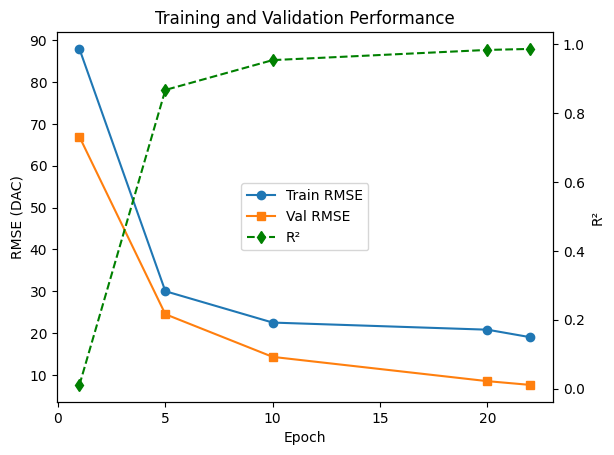

In [ ]:
import matplotlib.pyplot as plt

# Data
epochs = [1, 5, 10, 20, 22]
train_rmse = [87.9, 30.0, 22.5, 20.8, 19.0]
val_rmse = [66.9, 24.5, 14.3, 8.5, 7.6]
r2 = [0.0106, 0.8678, 0.9546, 0.9842, 0.9871]

fig, ax1 = plt.subplots()

# Plot RMSE curves (left y-axis)
ln1 = ax1.plot(epochs, train_rmse, 'o-', label="Train RMSE")
ln2 = ax1.plot(epochs, val_rmse, 's-', label="Val RMSE")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("RMSE (DAC)")

# Plot R² curve (right y-axis)
ax2 = ax1.twinx()
ln3 = ax2.plot(epochs, r2, 'd--', color="green", label="R²")
ax2.set_ylabel("R²")

# Combine legends
lines = ln1 + ln2 + ln3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="center")

plt.title("Training and Validation Performance")
plt.show()


In [ ]:
import numpy as np
import torch
from torch.utils.data import Dataset
from typing import List

# check if sequence is not
class MultiSensorDataset(Dataset):
    def __init__(self,
                 stacks: List[np.ndarray],
                 rates:  List[np.ndarray]):
        """
        stacks: list of arrays shaped (n_steps, H, W)
        rates:  list of arrays shaped (H, W)
        """
        self.examples = []
        for stack, rate in zip(stacks, rates):
            n_steps, H, W = stack.shape
            # flatten into (H*W, n_steps)
            flat = torch.from_numpy(
                stack.transpose(1,2,0).reshape(-1, n_steps)
            ).float()
            # flatten targets into (H*W,)
            tgt  = torch.from_numpy(rate.reshape(-1)).float()
            # store each pixel‐vector + its target
            for vec, t in zip(flat, tgt):
                self.examples.append((vec.unsqueeze(1), t))

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):
        return self.examples[idx]


In [ ]:
import torch
from torch.utils.data import Dataset

class PixelDataset(Dataset):
    def __init__(self, sensor_stack, rate_map):
        n_steps, H, W = sensor_stack.shape
        flat = torch.from_numpy(
            sensor_stack.transpose(1,2,0).reshape(-1, n_steps)
        ).float()                    # (H*W, n_steps)
        self.x = [v.unsqueeze(1) for v in flat]
        self.y = torch.from_numpy(rate_map.reshape(-1)).float()

    def __len__(self):
        return len(self.x)

    def __getitem__(self, i):
        return self.x[i], self.y[i]


In [ ]:
#    The collate function: takes a list of (seq, target) and
#    returns (padded_seqs, lengths, targets) for that batch

def collate_batch(batch):
    seqs, targets = zip(*batch) # unzip a list of tuples
    lengths = torch.LongTensor([len(s) for s in seqs])
    # sort by descending length
    lengths, perm = lengths.sort(descending=True)
    seqs    = [seqs[i] for i in perm]
    targets = torch.stack([targets[i] for i in perm])
    # pad to the length of the longest sequence in this batch
    padded = pad_sequence(seqs, batch_first=True, padding_value=0.0)
    return padded, lengths, targets

In [ ]:
# install a loading bar to see the training's progress real-time
!pip install tqdm

In [ ]:
import torch
from torch.utils.data import DataLoader

# Collect your stacks and rates into lists:
stacks = [
    sensor_stack_1,
    sensor_stack_2,
    sensor_stack_3,
    sensor_stack_4,
    sensor_stack_5,
    sensor_stack_6,
    sensor_stack_7,
    sensor_stack_8,
    sensor_stack_9,
    sensor_stack_10,
]
rates = rate_list   # [rate_1, rate_2, ..., rate_6]

# Build the multi‐sensor dataset & loader
dataset = MultiSensorDataset(stacks, rates)
loader  = DataLoader(
    dataset,
    batch_size=512,
    shuffle=True,
    collate_fn=collate_batch,
    drop_last=True
)

# Prepare model, optimizer, loss ---------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model  = PixelRNN(hidden_size=32, dense_size=16, dropout=0.2).to(device)
opt    = torch.optim.Adam(model.parameters(), lr=1e-3)
crit   = torch.nn.MSELoss()

all_rates_flat = np.concatenate([r.reshape(-1) for r in rate_list])
y_min, y_max   = float(all_rates_flat.min()), float(all_rates_flat.max())
y_range        = y_max - y_min

## Training on normalized values

Epoch 01 ― Train RMSE: 87.9 DAC  Val RMSE: 66.9 DAC  R²: 0.0106
  → checkpoint saved


Epoch 02 ― Train RMSE: 68.0 DAC  Val RMSE: 64.6 DAC  R²: 0.0782
  → checkpoint saved


Epoch 03 ― Train RMSE: 49.1 DAC  Val RMSE: 32.2 DAC  R²: 0.7714
  → checkpoint saved


Epoch 04 ― Train RMSE: 33.8 DAC  Val RMSE: 27.5 DAC  R²: 0.8325
  → checkpoint saved


Epoch 05 ― Train RMSE: 30.0 DAC  Val RMSE: 24.5 DAC  R²: 0.8678
  → checkpoint saved


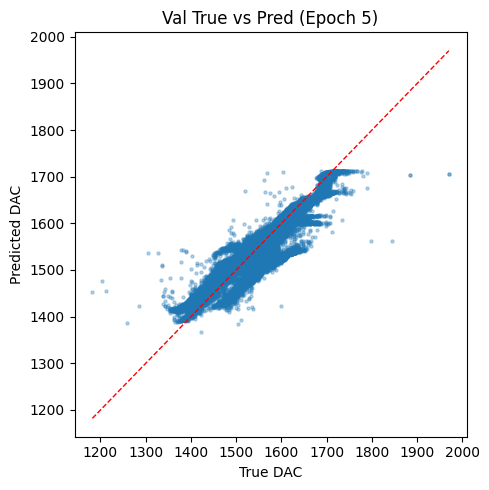

Epoch 06 ― Train RMSE: 28.3 DAC  Val RMSE: 27.0 DAC  R²: 0.8385


Epoch 07 ― Train RMSE: 26.9 DAC  Val RMSE: 21.1 DAC  R²: 0.9012
  → checkpoint saved


Epoch 08 ― Train RMSE: 24.9 DAC  Val RMSE: 15.4 DAC  R²: 0.9478
  → checkpoint saved


Epoch 09 ― Train RMSE: 23.3 DAC  Val RMSE: 16.9 DAC  R²: 0.9370


Epoch 10 ― Train RMSE: 22.5 DAC  Val RMSE: 14.3 DAC  R²: 0.9546
  → checkpoint saved


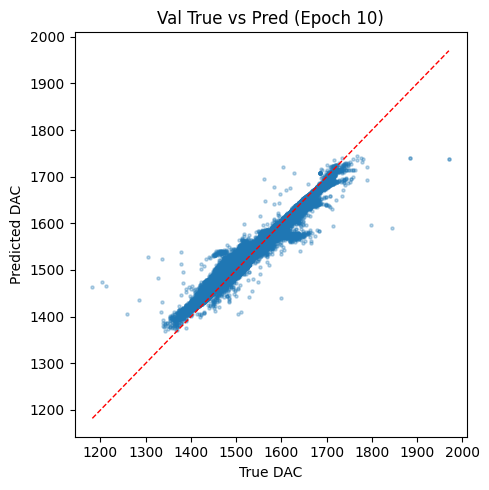

Epoch 11 ― Train RMSE: 21.5 DAC  Val RMSE: 10.6 DAC  R²: 0.9752
  → checkpoint saved


Epoch 12 ― Train RMSE: 20.7 DAC  Val RMSE: 9.7 DAC  R²: 0.9791
  → checkpoint saved


Epoch 13 ― Train RMSE: 21.2 DAC  Val RMSE: 10.7 DAC  R²: 0.9746


Epoch 14 ― Train RMSE: 21.2 DAC  Val RMSE: 9.2 DAC  R²: 0.9812
  → checkpoint saved


Epoch 15 ― Train RMSE: 20.5 DAC  Val RMSE: 9.5 DAC  R²: 0.9800


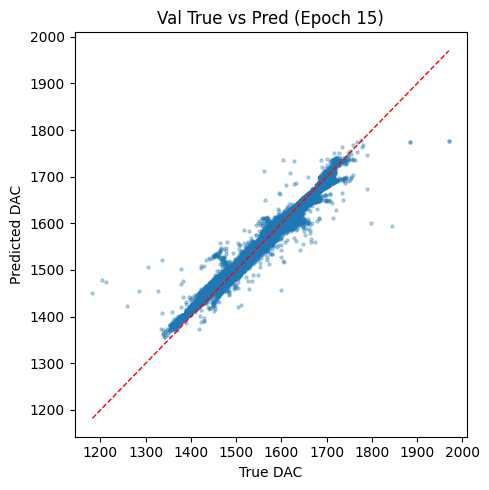

Epoch 16 ― Train RMSE: 21.0 DAC  Val RMSE: 10.0 DAC  R²: 0.9777


Epoch 17 ― Train RMSE: 20.8 DAC  Val RMSE: 18.0 DAC  R²: 0.9284


Epoch 18 ― Train RMSE: 21.6 DAC  Val RMSE: 9.3 DAC  R²: 0.9810


Epoch 19 ― Train RMSE: 20.9 DAC  Val RMSE: 10.7 DAC  R²: 0.9748


Epoch 20 ― Train RMSE: 20.8 DAC  Val RMSE: 8.5 DAC  R²: 0.9842
  → checkpoint saved


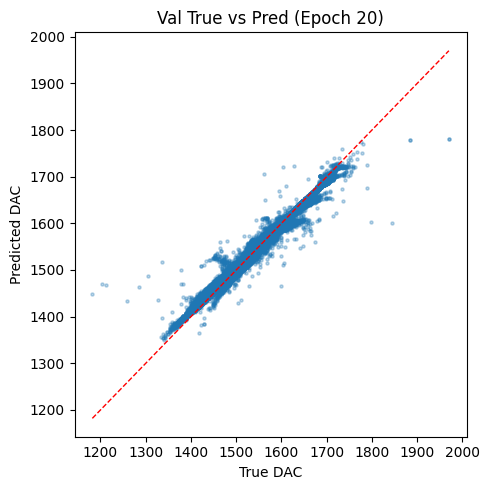

Epoch 21 ― Train RMSE: 21.0 DAC  Val RMSE: 18.7 DAC  R²: 0.9225


Epoch 22 ― Train RMSE: 19.0 DAC  Val RMSE: 7.6 DAC  R²: 0.9871
  → checkpoint saved


Epoch 23 ― Train RMSE: 21.6 DAC  Val RMSE: 11.0 DAC  R²: 0.9734


Epoch 24 ― Train RMSE: 20.4 DAC  Val RMSE: 8.0 DAC  R²: 0.9860


Epoch 25 ― Train RMSE: 25.9 DAC  Val RMSE: 19.7 DAC  R²: 0.9140


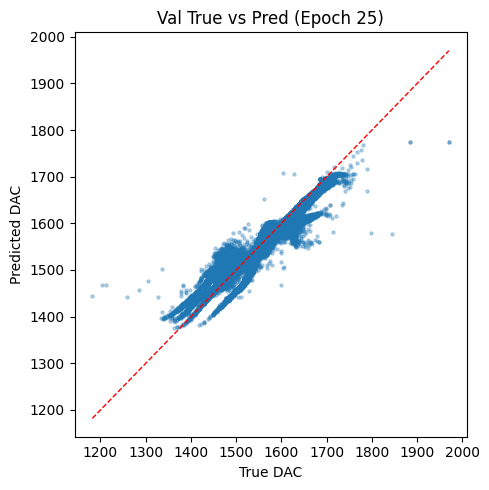

Epoch 26 ― Train RMSE: 24.3 DAC  Val RMSE: 8.6 DAC  R²: 0.9836


Epoch 27 ― Train RMSE: 19.9 DAC  Val RMSE: 8.4 DAC  R²: 0.9842


Epoch 28 ― Train RMSE: 21.1 DAC  Val RMSE: 10.0 DAC  R²: 0.9778


Epoch 29 ― Train RMSE: 20.3 DAC  Val RMSE: 9.8 DAC  R²: 0.9788


Epoch 30 ― Train RMSE: 22.5 DAC  Val RMSE: 23.6 DAC  R²: 0.8767
Stopping early after 8 epochs without improvement.


In [ ]:
import os
import torch
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
from tqdm import tqdm

# 0) Prepare checkpoint directory
CKPT_PATH = '/content/drive/MyDrive/magisterka/checkpoints/15_07_2025/pixel_rnn.pt'
os.makedirs(os.path.dirname(CKPT_PATH), exist_ok=True)

# split dataset into training & validation
val_frac   = 0.1
n_val      = int(len(dataset) * val_frac)
n_train    = len(dataset) - n_val
train_ds, val_ds = random_split(dataset, [n_train, n_val])

train_loader = DataLoader(train_ds, batch_size=512, shuffle=True,
                          collate_fn=collate_batch, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=512, shuffle=False,
                          collate_fn=collate_batch)

train_rmse_list = []
val_rmse_list   = []
val_r2_list     = []

# Early-stopping parameters
best_val_rmse = float('inf')
patience      = 8
wait          = 0

# Training loop with validation, R², scatter, checkpointing
num_epochs = 40
for epoch in range(1, num_epochs+1):
    # --- Training ---
    model.train()
    train_loss = 0.0
    for padded, lengths, targets in tqdm(train_loader, desc=f"Train E{epoch:02d}", leave=False):
        padded, lengths, targets = (padded.to(device), lengths.to(device), targets.to(device))
        targets_s = (targets - y_min) / y_range

        preds_s = model(padded, lengths)
        loss    = crit(preds_s, targets_s)

        opt.zero_grad()
        loss.backward()
        opt.step()

        train_loss += loss.item() * targets.size(0)

    avg_train_mse = train_loss / n_train
    train_rmse    = (avg_train_mse ** .5) * y_range

    # append to later show the comparison
    train_rmse_list.append(train_rmse)

    # --- Validation ---
    model.eval()
    val_trues = []
    val_preds = []
    with torch.no_grad():
        for padded, lengths, targets in val_loader:
            padded, lengths = padded.to(device), lengths.to(device)
            targets = targets.to(device)
            targets_s = (targets - y_min) / y_range

            preds_s = model(padded, lengths)
            preds   = preds_s * y_range + y_min

            val_trues.append(targets.cpu())
            val_preds.append(preds.cpu())
    y_true = torch.cat(val_trues).numpy()
    y_pred = torch.cat(val_preds).numpy()

    val_mse  = mean_squared_error(y_true, y_pred)
    val_rmse = val_mse ** .5
    val_r2   = r2_score(y_true, y_pred)

    # update for statistics
    val_rmse_list.append(val_rmse)
    val_r2_list.append(val_r2)

    # --- Report & Early Stopping ---
    print(f"Epoch {epoch:02d} ― Train RMSE: {train_rmse:.1f} DAC  "
          f"Val RMSE: {val_rmse:.1f} DAC  R²: {val_r2:.4f}")

    # save & reset patience if improved
    if val_rmse < best_val_rmse:
        best_val_rmse = val_rmse
        wait = 0
        torch.save({
            'epoch': epoch,
            'model_state': model.state_dict(),
            'opt_state':   opt.state_dict(),
            'y_min':       y_min,
            'y_range':     y_range
        }, CKPT_PATH)
        print("  → checkpoint saved")
    else:
        wait += 1
        if wait >= patience:
            print(f"Stopping early after {patience} epochs without improvement.")
            break

    # --- Scatter plot on validation at every epoch ---
    if epoch % 5 == 0:
        plt.figure(figsize=(5,5))
        plt.scatter(y_true, y_pred, alpha=0.3, s=5)
        mn, mx = y_true.min(), y_true.max()
        plt.plot([mn,mx],[mn,mx],'r--', lw=1)
        plt.xlabel('True DAC')
        plt.ylabel('Predicted DAC')
        plt.title(f'Val True vs Pred (Epoch {epoch})')
        plt.tight_layout()
        plt.show()


## Plot metrics

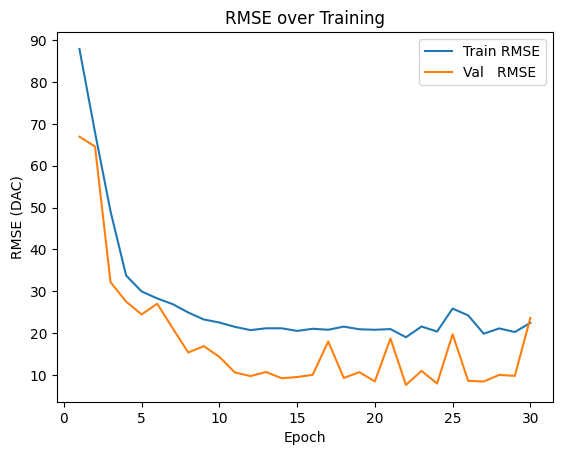

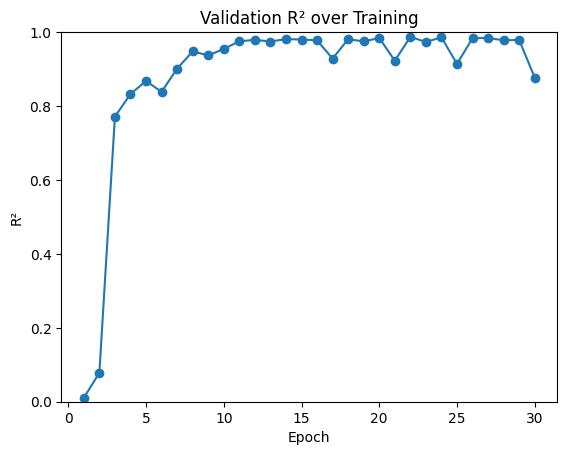

Final  MAE: 16.58 DAC


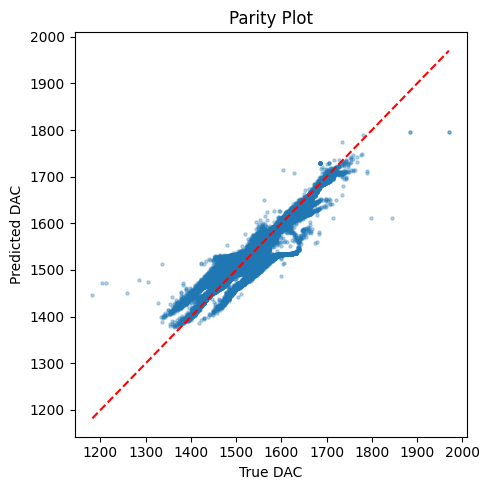

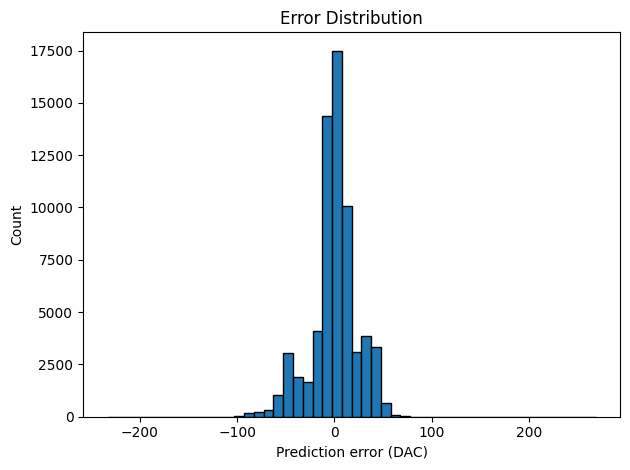

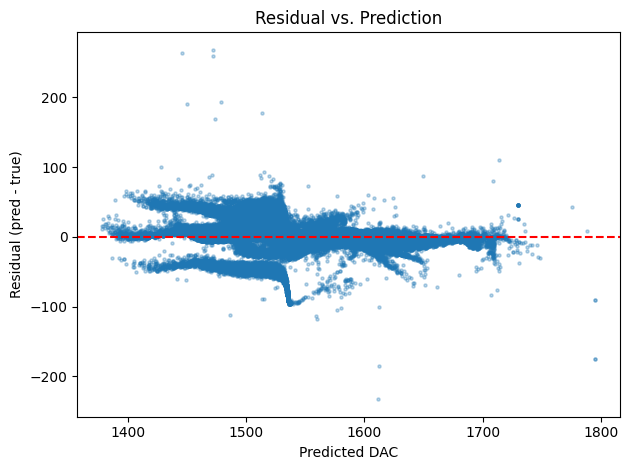

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

# --- 1) Plot RMSE & R² over epochs -------------------
epochs = np.arange(1, len(train_rmse_list)+1)

plt.figure()
plt.plot(epochs, train_rmse_list, label='Train RMSE')
plt.plot(epochs,   val_rmse_list,   label='Val   RMSE')
plt.xlabel('Epoch'); plt.ylabel('RMSE (DAC)')
plt.title('RMSE over Training'); plt.legend(); plt.show()

plt.figure()
plt.plot(epochs, val_r2_list, marker='o')
plt.xlabel('Epoch'); plt.ylabel('R²')
plt.title('Validation R² over Training')
plt.ylim(0,1)
plt.show()


# --- 2) Collect true vs. pred on the full val/test set --
y_trues, y_preds = [], []
model.eval()
with torch.no_grad():
    for padded, lengths, targets in val_loader:   # or test_loader
        padded, lengths = padded.to(device), lengths.to(device)
        targets = targets.to(device)
        preds_s = model(padded, lengths)
        preds   = preds_s * y_range + y_min
        y_trues.append(targets.cpu().numpy())
        y_preds.append(preds.cpu().numpy())

y_true = np.concatenate(y_trues)
y_pred = np.concatenate(y_preds)
errors = y_pred - y_true

print(f"Final  MAE: {mean_absolute_error(y_true, y_pred):.2f} DAC")

# --- 3) Parity plot & residual histogram ------------
plt.figure(figsize=(5,5))
plt.scatter(y_true, y_pred, alpha=0.3, s=5)
mn, mx = y_true.min(), y_true.max()
plt.plot([mn,mx],[mn,mx],'r--')
plt.xlabel('True DAC'); plt.ylabel('Predicted DAC')
plt.title('Parity Plot')
plt.tight_layout(); plt.show()

plt.figure()
plt.hist(errors, bins=50, edgecolor='k')
plt.xlabel('Prediction error (DAC)'); plt.ylabel('Count')
plt.title('Error Distribution')
plt.tight_layout(); plt.show()

# --- 4) Residual vs. Predicted -----------------------
plt.figure()
plt.scatter(y_pred, errors, alpha=0.3, s=5)
plt.axhline(0, color='r', ls='--')
plt.xlabel('Predicted DAC'); plt.ylabel('Residual (pred - true)')
plt.title('Residual vs. Prediction')
plt.tight_layout(); plt.show()



## See example input/output

In [ ]:
import torch
import numpy as np

# 1) Select a pixel to inspect, e.g. (row=0, col=0) on sensor 1
row, col = 89, 233

# 2) Build the raw input sequence from your sensor_stack_1
vec = torch.from_numpy(sensor_stack_1[:, row, col]).float()  # shape (n_steps,)

# 3) Print the raw sequence (you can truncate if it’s long)
print("Input sequence:")
print(vec.numpy()[:])

# 4) Run it through the model to get a prediction
model.eval()
with torch.no_grad():
    seq   = vec.unsqueeze(1).to(device)            # (n_steps,1)
    padded= seq.unsqueeze(0)                       # (1,n_steps,1)
    lengths = torch.LongTensor([seq.size(0)]).to(device)
    pred_s  = model(padded, lengths).item()        # scaled [0,1]
# back‐transform to DAC
pred_dac = pred_s * y_range + y_min

# 5) (Optional) get the true threshold from your rate map
true_dac = rates[0][row, col]

print(f"True DAC threshold at pixel ({row},{col}) : {true_dac:.1f}")
print(f"Model’s predicted threshold         : {pred_dac:.1f}")


Input sequence:
[ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  1.  3.  3. 53. 63. 63. 63. 63. 63. 63. 63. 63. 63.
 63. 63. 63. 63. 63. 63. 63. 22.  2.  2.  1.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
True DAC threshold at pixel (89,233) : 1627.0
Model’s predicted threshold         : 1627.3


## Show metrics for all sensors included in the training process

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import torch
from torch.utils.data import DataLoader

sensor_info = [
    [1395, 1845,  90],  # (1845-1395)/5 = 90
    [1235, 1790, 111],  # (1790-1235)/5 = 111
    [1290, 1885, 119],  # (1885-1290)/5 = 119
    [1340, 1980, 128],  # (1980-1340)/5 = 128
    [1195, 1780, 117],  # (1780-1195)/5 = 117
    [1145, 1705, 112],  # (1705-1145)/5 = 112
    [1185, 1735, 110],  # (1735 - 1185) / 5 = 110
    [1185, 1750, 113],  # (1750 - 1185) / 5 = 113
    [1175, 1720, 109],  # (1720 - 1175) / 5 = 109
    [1365, 1970, 121],  # (1970 - 1365) / 5 = 121
]

for i, (stack, rate) in enumerate(zip(stacks, rates), start=1):
    # build a single‐sensor dataset & loader
    ds    = MultiSensorDataset([stack], [rate])
    loader = DataLoader(ds,
                        batch_size=512,
                        shuffle=False,
                        collate_fn=collate_batch)

    # run inference
    model.eval()
    y_true_list = []
    y_pred_list = []
    with torch.no_grad():
        for padded, lengths, targets in loader:
            padded, lengths = padded.to(device), lengths.to(device)
            targets = targets.to(device)

            pred_s = model(padded, lengths)
            pred   = pred_s * y_range + y_min

            y_true_list.append(targets.cpu().numpy())
            y_pred_list.append(pred.cpu().numpy())

    y_true = np.concatenate(y_true_list)
    y_pred = np.concatenate(y_pred_list)

    # compute metrics
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)

    print(f"Sensor {i} results:")
    print(f"  Min threshold: {sensor_info[i-1][0]}, Max treshold: {sensor_info[i-1][1]}, Vector length: {sensor_info[i-1][2]}")
    print(f"  MAE:  {mae: .2f} DAC")
    print(f"  RMSE: {rmse: .2f} DAC")
    print(f"  R²:   {r2:.4f}\n")


Sensor 1 results:
  Min threshold: 1395, Max treshold: 1845, Vector length: 90
  MAE:   3.58 DAC
  RMSE:  5.82 DAC
  R²:   0.9750

Sensor 2 results:
  Min threshold: 1235, Max treshold: 1790, Vector length: 111
  MAE:   49.55 DAC
  RMSE:  50.89 DAC
  R²:   -0.9491

Sensor 3 results:
  Min threshold: 1290, Max treshold: 1885, Vector length: 119
  MAE:   15.79 DAC
  RMSE:  18.24 DAC
  R²:   0.7968

Sensor 4 results:
  Min threshold: 1340, Max treshold: 1980, Vector length: 128
  MAE:   5.96 DAC
  RMSE:  8.51 DAC
  R²:   0.9644

Sensor 5 results:
  Min threshold: 1195, Max treshold: 1780, Vector length: 117
  MAE:   4.55 DAC
  RMSE:  7.50 DAC
  R²:   0.9621

Sensor 6 results:
  Min threshold: 1145, Max treshold: 1705, Vector length: 112
  MAE:   34.31 DAC
  RMSE:  35.74 DAC
  R²:   0.0262

Sensor 7 results:
  Min threshold: 1185, Max treshold: 1735, Vector length: 110
  MAE:   9.43 DAC
  RMSE:  10.84 DAC
  R²:   0.9089

Sensor 8 results:
  Min threshold: 1185, Max treshold: 1750, Vector l

## Per-sensor evaluation and plots

In [ ]:
import os, numpy as np, torch, matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# where to save figures
PLOT_DIR = '/content/drive/MyDrive/magisterka/figs_per_sensor'
os.makedirs(PLOT_DIR, exist_ok=True)

def eval_and_plot_sensor(sensor_idx, stack, rate, name=None,
                         make_heatmap=False):
    """
    sensor_idx: 1-based index for labeling
    stack: np.ndarray (T, 256, 256)
    rate:  np.ndarray (256, 256)
    name:  optional string label used in filenames
    make_heatmap: also save a spatial error map (slower)
    """
    label = name or f"sensor{sensor_idx}"

    # --- build a per-sensor loader
    ds = MultiSensorDataset([stack], [rate])
    loader = DataLoader(ds, batch_size=512, shuffle=False, collate_fn=collate_batch)

    # --- inference
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for padded, lengths, targets in loader:
            padded, lengths = padded.to(device), lengths.to(device)
            targets         = targets.to(device)

            pred_s = model(padded, lengths)
            pred   = pred_s * y_range + y_min

            y_true.append(targets.cpu().numpy())
            y_pred.append(pred.cpu().numpy())

    y_true = np.concatenate(y_true)
    y_pred = np.concatenate(y_pred)
    errors = y_pred - y_true

    # --- metrics
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    print(f"[{label}] MAE={mae:.2f}  RMSE={rmse:.2f}  R²={r2:.4f}")

    # --- parity plot
    plt.figure(figsize=(5,5))
    plt.scatter(y_true, y_pred, alpha=0.3, s=5)
    mn, mx = y_true.min(), y_true.max()
    plt.plot([mn, mx], [mn, mx], 'r--', lw=1)
    plt.xlabel('True DAC')
    plt.ylabel('Predicted DAC')
    plt.title(f'{label}: True vs Predicted')
    plt.tight_layout()
    parity_path = os.path.join(PLOT_DIR, f'{label}_parity.png')
    plt.savefig(parity_path, dpi=150)
    plt.close()

    # --- residuals vs prediction
    plt.figure(figsize=(6,4))
    plt.scatter(y_pred, errors, alpha=0.3, s=5)
    plt.axhline(0, color='r', ls='--')
    plt.xlabel('Predicted DAC')
    plt.ylabel('Residual (pred - true) [DAC]')
    plt.title(f'{label}: Residual vs Predicted')
    plt.tight_layout()
    resid_path = os.path.join(PLOT_DIR, f'{label}_residuals.png')
    plt.savefig(resid_path, dpi=150)
    plt.close()

    # --- optional spatial error map (needs exact per-sensor pixel order)
    heatmap_path = None
    if make_heatmap:
        err_map = errors.reshape(256, 256)
        vmax = np.max(np.abs(err_map))
        plt.figure(figsize=(6,5))
        plt.imshow(err_map, cmap='bwr', vmin=-vmax, vmax=vmax)
        plt.colorbar(label='Error (DAC)')
        plt.title(f'{label}: Spatial Error Map')
        plt.tight_layout()
        heatmap_path = os.path.join(PLOT_DIR, f'{label}_errmap.png')
        plt.savefig(heatmap_path, dpi=150)
        plt.close()

    return {'mae': mae, 'rmse': rmse, 'r2': r2,
            'parity': parity_path, 'residuals': resid_path,
            'heatmap': heatmap_path}

# ---- run for the 10 training sensors ----
per_sensor_outputs = []
for i, (stack, rate) in enumerate(zip(stacks, rates), start=1):
    per_sensor_outputs.append(
        eval_and_plot_sensor(i, stack, rate, name=f"sensor{i}",
                             make_heatmap=False)   # set True if you want maps
    )

# If you specifically want extra visuals for weaker sensors:
# for bad in (2, 6, 8):
#     eval_and_plot_sensor(bad, stacks[bad-1], rates[bad-1],
#                          name=f"sensor{bad}_focus", make_heatmap=True)


## Plot error sensor maps

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

def plot_sensor_error_map(sensor_stack, rate_map, sensor_name):
    """
    Runs inference on one sensor and displays a 256×256 error heatmap.
    """
    # Build a DataLoader for this sensor
    ds = PixelDataset(sensor_stack, rate_map)
    loader = DataLoader(ds, batch_size=512, shuffle=False, collate_fn=collate_batch)

    # Collect predictions & truths
    model.eval()
    y_true_list, y_pred_list = [], []
    with torch.no_grad():
        for padded, lengths, targets in loader:
            padded, lengths = padded.to(device), lengths.to(device)
            # normalize inputs if you used global /63.0 scaling:
            # padded = padded.float() / 63.0
            preds_s = model(padded, lengths)
            preds   = preds_s * y_range + y_min
            y_true_list.append(targets.cpu().numpy())
            y_pred_list.append(preds.cpu().numpy())

    y_true = np.concatenate(y_true_list)   # shape (256*256,)
    y_pred = np.concatenate(y_pred_list)
    errors = y_pred - y_true

    # reshape to 256×256 grid
    err_map = errors.reshape(256, 256)

    # plot
    plt.figure(figsize=(5,5))
    plt.imshow(err_map, cmap='bwr',
               vmin=-np.max(np.abs(err_map)),
               vmax= np.max(np.abs(err_map)))
    plt.colorbar(label='Error (DAC)')
    plt.title(f'{sensor_name}: Spatial Error Map')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

sensor_stacks = [
    sensor_stack_1, sensor_stack_2, sensor_stack_3, sensor_stack_4,
    sensor_stack_5, sensor_stack_6, sensor_stack_7, sensor_stack_8,
    sensor_stack_9, sensor_stack_10
]
rate_maps = [
    rate_list[0], rate_list[1], rate_list[2], rate_list[3],
    rate_list[4], rate_list[5], rate_list[6], rate_list[7],
    rate_list[8], rate_list[9]
]

for idx, (stack, rate) in enumerate(zip(sensor_stacks, rate_maps), start=1):
    plot_sensor_error_map(stack, rate, sensor_name=f"Sensor {idx}")


## Check model validity for other sensors

In [ ]:
# Import data for sensor number 11

# 1185 1750
file_path_11 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP0-2_scan0_raw_1of1.csv'
velopix_data_11 = np.loadtxt(fname=file_path_11, delimiter=",", skiprows=1)

sensor_stack_11 = reshape_sensor_data(velopix_data_11, sensor_min=1185, sensor_max=1750)

header_11 = SimpleNamespace(
    min_thr    = 1185,
    max_thr    = 1750,
    step_size  =   5,
    vp         = 'Sensor 11',
    trim       =    0,
    readable   = 'DAC threshold scan for Sensor 11'
)

d_mean_11, d_std_11, rate_11 = ana.threshold_scan(
    velopix_data_11,
    header_11,
    save  = 0,
    slope = 'right',
    path  = out_folder
)

Processing a threshold scan...
...time for computing mean & std is  0.0982215404510498
...computing noise rate, time elapsed:  0.02760791778564453


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import torch
from torch.utils.data import DataLoader

# --- Build a single‐sensor loader for sensor 11 --------------
ds11    = PixelDataset(sensor_stack_11, rate_11)
loader11 = DataLoader(
    ds11,
    batch_size=512,
    shuffle=False,
    collate_fn=collate_batch
)

# --- Run inference on sensor 11 -------------------------------
model.eval()
y_trues, y_preds = [], []

with torch.no_grad():
    for padded, lengths, targets in loader11:
        padded, lengths = padded.to(device), lengths.to(device)
        targets = targets.to(device)

        # predict in normalized space, then back-transform
        pred_s = model(padded, lengths)
        pred   = pred_s * y_range + y_min

        y_trues.append(targets.cpu().numpy())
        y_preds.append(pred.cpu().numpy())

# flatten to 1-D arrays
y_true11 = np.concatenate(y_trues)  # shape (256*256,)
y_pred11 = np.concatenate(y_preds)

# --- Compute DAC-space metrics ---------------------------------
mse11  = mean_squared_error(y_true11, y_pred11)
rmse11 = np.sqrt(mse11)
mae11  = mean_absolute_error(y_true11, y_pred11)
r2_11  = r2_score(y_true11, y_pred11)

print(f"Sensor 11 results:")
print(f"  Min threshold: 1125, Max treshold: 1685, Vector length: 112")
print(f"  MAE:  {mae11: .2f} DAC")
print(f"  RMSE: {rmse11: .2f} DAC")
print(f"  R²:   {r2_11:.4f}")


Sensor 11 results:
  Min threshold: 1125, Max treshold: 1685, Vector length: 112
  MAE:   14.75 DAC
  RMSE:  17.24 DAC
  R²:   0.7773


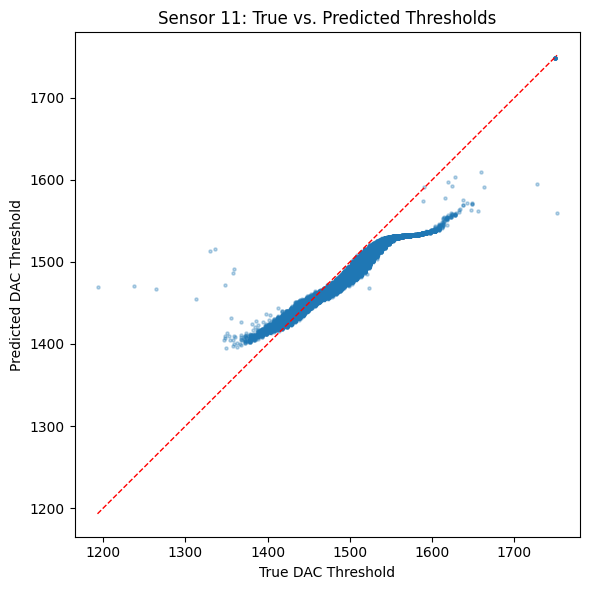

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Collect true vs. predicted for sensor 11
y_true11, y_pred11 = [], []

model.eval()
with torch.no_grad():
    for padded, lengths, targets in loader11:
        padded, lengths = padded.to(device), lengths.to(device)
        targets = targets.to(device)

        # Predict in normalized space, then back-transform
        pred_s = model(padded, lengths)
        pred   = pred_s * y_range + y_min

        y_true11.append(targets.cpu().numpy())
        y_pred11.append(pred.cpu().numpy())

# Flatten lists to arrays
y_true11 = np.concatenate(y_true11)
y_pred11 = np.concatenate(y_pred11)

# Scatter plot: True vs Predicted
plt.figure(figsize=(6,6))
plt.scatter(y_true11, y_pred11, alpha=0.3, s=5)
mn, mx = y_true11.min(), y_true11.max()
plt.plot([mn, mx], [mn, mx], 'r--', linewidth=1)
plt.xlabel('True DAC Threshold')
plt.ylabel('Predicted DAC Threshold')
plt.title('Sensor 11: True vs. Predicted Thresholds')
plt.tight_layout()
plt.show()


## Check validity for sensor 12

Processing a threshold scan...
...time for computing mean & std is  0.3216431140899658
...computing noise rate, time elapsed:  0.04142284393310547
Sensor 12 results:
  Min threshold: 1355, Max threshold: 1980, Vector length: 125
  MAE:   9.69 DAC
  RMSE:  17.87 DAC
  R²:   0.8907


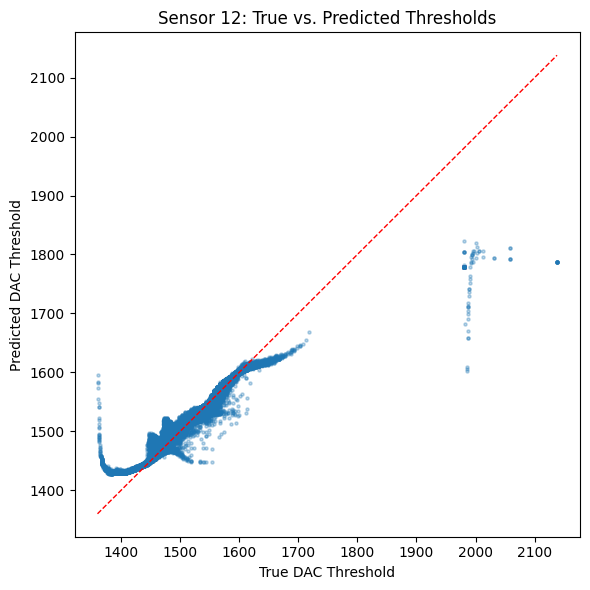

In [ ]:
import numpy as np
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# 1355 1980
file_path_12 = '/content/drive/MyDrive/magisterka/data_velopix/Module00_VP2-0_scan0_raw_1of1.csv'
velopix_data_12 = np.loadtxt(fname=file_path_12, delimiter=",", skiprows=1)


# 1) Load & reshape sensor 12
sensor_stack_12 = reshape_sensor_data(velopix_data_12,
                                      sensor_min=1355,
                                      sensor_max=1980)
# 2) Compute its rate map
header_12 = SimpleNamespace(
    min_thr   = 1355,
    max_thr   = 1980,
    step_size =   5,
    vp        = 'Sensor 12',
    trim      =   0,
    readable  = 'DAC threshold scan for Sensor 12'
)
_, _, rate_12 = ana.threshold_scan(
    velopix_data_12,
    header_12,
    save  = 0,
    slope = 'right',
    path  = out_folder
)

# 3) Build a DataLoader for sensor 12
ds12   = PixelDataset(sensor_stack_12, rate_12)
loader12 = DataLoader(
    ds12,
    batch_size=512,
    shuffle=False,
    collate_fn=collate_batch
)

# 4) Run inference and collect true vs. predicted
model.eval()
y_trues, y_preds = [], []
with torch.no_grad():
    for padded, lengths, targets in loader12:
        padded, lengths = padded.to(device), lengths.to(device)
        targets = targets.to(device)

        pred_s = model(padded, lengths)
        pred   = pred_s * y_range + y_min

        y_trues.append(targets.cpu().numpy())
        y_preds.append(pred.cpu().numpy())

y_true12 = np.concatenate(y_trues)
y_pred12 = np.concatenate(y_preds)

# 5) Compute metrics
mse12  = mean_squared_error(y_true12, y_pred12)
rmse12 = np.sqrt(mse12)
mae12  = mean_absolute_error(y_true12, y_pred12)
r2_12  = r2_score(y_true12, y_pred12)

print(f"Sensor 12 results:")
print(f"  Min threshold: 1355, Max threshold: 1980, Vector length: {(1980-1355)//5}")
print(f"  MAE:  {mae12: .2f} DAC")
print(f"  RMSE: {rmse12: .2f} DAC")
print(f"  R²:   {r2_12:.4f}")

# 6) Parity plot
plt.figure(figsize=(6,6))
plt.scatter(y_true12, y_pred12, alpha=0.3, s=5)
mn, mx = y_true12.min(), y_true12.max()
plt.plot([mn, mx], [mn, mx], 'r--', linewidth=1)
plt.xlabel('True DAC Threshold')
plt.ylabel('Predicted DAC Threshold')
plt.title('Sensor 12: True vs. Predicted Thresholds')
plt.tight_layout()
plt.show()
